# 04 — Does a more flexible covariance model help?

The scalar benchmark left some USD variance/covariance dependence. Keep the **same constant
world/local pricing equations and frozen sample**, and allow each market to have its own shock
response and volatility persistence. Estimate a diagonal BEKK model jointly with the risk prices;
compare fit, uncertainty and residuals with notebook 03 before introducing currency prices.

Run `dataset.ipynb`, `03_pricing_baseline.ipynb`, then **Run All** here in the existing Miniconda
**base** kernel. This notebook reads local files only. Settings are in the first cell; the final table
summarises the comparison. Saved fits are checked before reuse.

In [1]:
# Adjustable settings. Never fetch data or change the frozen snapshot in this notebook.
SNAPSHOT = "data/fixed_2026-11-13/from_2000-01"
ANALYSIS_START = None
ANALYSIS_END = None
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70), (0.02, 0.96)]  # common alpha, beta starts
MIXED_ALPHA = [0.04, 0.08, 0.03]  # World, US, Hungary
MIXED_BETA = [0.92, 0.80, 0.92]
MAX_ITER = 900
TEST_LAGS = 12
REUSE_FITS = True  # False forces re-estimation. Change MODEL_VERSION after model-code edits.
MODEL_VERSION = "diagonal_bekk_garch_m_v1"

from pathlib import Path
from io import BytesIO
import hashlib
import importlib.metadata
import json
import os
import platform
import sys

ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import softmax
from scipy.stats import norm, chi2
from packaging.version import Version
sm_version = importlib.metadata.version("statsmodels")
if Version(sm_version) < Version("0.15.0"):
    raise RuntimeError("Run %pip install --upgrade statsmodels==0.15.0, then Restart Kernel and Run All.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != sm_version:
    raise RuntimeError("statsmodels was updated. Restart Kernel and Run All to discard old imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from IPython.display import display, Markdown

versions = {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]}
print("Python:", sys.executable)
print("Packages:", versions)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
source = ROOT / SNAPSHOT
manifest = json.loads((source / "manifest.json").read_text())
raw = (source / "dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest() != manifest["exports"]["dataset.csv"]:
    raise ValueError("The frozen dataset is not sealed or its checksum differs.")
data = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
data.index = pd.PeriodIndex(data.index, freq="M", name="month")
if not data.index.equals(pd.period_range(data.index[0], data.index[-1], freq="M")):
    raise ValueError("Missing or duplicate months.")
data = data.loc[ANALYSIS_START:ANALYSIS_END].copy()
if len(data) < max(120, 5 * TEST_LAGS) or not 2 <= TEST_LAGS <= 24:
    raise ValueError("Use at least 120 months and TEST_LAGS from 2 to 24 for this initial fit.")
ASSETS = ["World", "US", "Hungary"]
samples = {c: data[[f"rx_{a}_{c.lower()}" for a in ["world", "us", "hu"]]].to_numpy() * 100
           for c in ["USD", "EUR"]}
if not all(np.isfinite(y).all() for y in samples.values()):
    raise ValueError("Non-finite returns.")
scales_by_currency = {c: y.std(axis=0, ddof=1) for c, y in samples.items()}
if not all((s > 0).all() for s in scales_by_currency.values()):
    raise ValueError("A return series is constant.")
BASELINE = ROOT / "output" / "03_pricing_baseline" / source.parent.name / f"{data.index[0]}_{data.index[-1]}"
OUT = ROOT / "output" / "04_covariance_comparison" / source.parent.name / f"{data.index[0]}_{data.index[-1]}"
OUT.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame({"first": [str(data.index[0])], "last": [str(data.index[-1])],
                      "months": [len(data)], "assets": [", ".join(ASSETS)], "return_unit": ["monthly log %"]}))
prior_manifest = json.loads((BASELINE / "estimation_manifest.json").read_text())
if (prior_manifest["source_dataset_sha256"] != manifest["exports"]["dataset.csv"]
        or prior_manifest["first"] != str(data.index[0]) or prior_manifest["last"] != str(data.index[-1])
        or prior_manifest["assets"] != ASSETS or prior_manifest["model_version"] != "scalar_bekk_garch_m_v1"):
    raise ValueError("Run notebook 03 on exactly the same snapshot and sample first.")
baseline_hashes = {}
def baseline_bytes(name):
    content = (BASELINE / name).read_bytes()
    baseline_hashes[name] = hashlib.sha256(content).hexdigest()
    return content
baseline_bytes("estimation_manifest.json")

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


,first,last,months,assets,return_unit
0,2000-01,2026-09,321,"World, US, Hungary",monthly log %


b'{\n  "assets": [\n    "World",\n    "US",\n    "Hungary"\n  ],\n  "covariance": "scalar BEKK, jointly estimated long-run innovation covariance; H0=Sigma",\n  "first": "2000-01",\n  "last": "2026-09",\n  "model_version": "scalar_bekk_garch_m_v1",\n  "observations": 321,\n  "packages": {\n    "matplotlib": "3.10.8",\n    "numpy": "2.4.4",\n    "pandas": "3.0.2",\n    "scipy": "1.17.1",\n    "statsmodels": "0.15.0"\n  },\n  "python": "3.13.12",\n  "return_unit": "monthly log percentage points",\n  "risk_prices": "constant, unrestricted sign; currency terms omitted",\n  "source_dataset_sha256": "78117c8baf1a370d70450626bc1aeb66ec8b27f7afefa4c80d296284f68efff5",\n  "source_snapshot": "data/fixed_2026-11-13/from_2000-01",\n  "test_lags": 12\n}\n'

## 1. Change the covariance process only

For asset order World, US, Hungary, the unchanged pricing restrictions are

$$\mu_{W,t}=\lambda_W H_{WW,t},\qquad
\mu_{US,t}=\lambda_W H_{US,W,t}+\lambda_{US}H_{US,US,t},\qquad
\mu_{HU,t}=\lambda_W H_{HU,W,t}+\lambda_{HU}H_{HU,HU,t}.$$

`world_only` fixes both local prices to zero; `world_local` estimates all three. Prices have unrestricted
sign. Returns are monthly excess log returns in percentage points, matching notebook 03.

**The new covariance equation is**

$$\boxed{H_t=CC'+A\varepsilon_{t-1}\varepsilon_{t-1}'A'+BH_{t-1}B',\quad
A=\operatorname{diag}(\sqrt{\alpha_i}),\quad B=\operatorname{diag}(\sqrt{\beta_i}).}$$

A free lower-triangular $C$ with positive diagonal makes the intercept positive definite. For each
asset, a softmax sets $\alpha_i>0$, $\beta_i>0$, $\alpha_i+\beta_i<1$. Thus
$|\sqrt{\alpha_i\alpha_j}+\sqrt{\beta_i\beta_j}|<1$ for every pair, ensuring covariance stationarity
for this diagonal recursion. Start at its implied long-run innovation covariance:

$$H_{0,ij}=\Sigma_{ij}=\frac{(CC')_{ij}}{1-\sqrt{\alpha_i\alpha_j}-\sqrt{\beta_i\beta_j}}.$$

This is the diagonal BEKK form of the [Engle–Kroner covariance family](https://doi.org/10.1017/S0266466600009063).
Here diagonal coefficients are restricted to be nonnegative; there are no asymmetric shock terms.
This is a covariance robustness check, not an exact reproduction of the paper's parameterisation.

There are **13 parameters** under world-only and **15** under world/local: six intercept coordinates,
six dynamic coordinates, and one or three prices. The scalar benchmark is exactly nested by setting
all $\alpha_i=\alpha$ and $\beta_i=\beta$, with $CC'=(1-\alpha-\beta)\Sigma$.

In [2]:
PRICE_SCALE = 0.01
TRI = np.tril_indices(3)

def unpack(theta, scales, partial):
    k, q = (3 if partial else 1), len(theta)
    prices, dp = np.zeros(3), np.zeros((q, 3))
    prices[:k] = PRICE_SCALE * theta[:k]
    dp[np.arange(k), np.arange(k)] = PRICE_SCALE
    L, dL = np.zeros((3, 3)), np.zeros((q, 3, 3))
    for offset, (i, j) in enumerate(zip(*TRI)):
        index = k + offset
        L[i, j] = np.exp(theta[index]) if i == j else theta[index]
        dL[index, i, j] = L[i, j] if i == j else 1.0
    C, dC = scales[:, None] * L, scales[None, :, None] * dL
    intercept = C @ C.T
    dintercept = dC @ C.T + C @ dC.transpose(0, 2, 1)
    weights = softmax(np.c_[np.zeros(3), theta[-6:].reshape(3, 2)], axis=1)
    alpha, beta = weights[:, 1], weights[:, 2]
    da, db = np.zeros((q, 3)), np.zeros((q, 3))
    for i in range(3):
        u, v = k + 6 + 2 * i, k + 7 + 2 * i
        da[u, i], da[v, i] = alpha[i] * (1 - alpha[i]), -alpha[i] * beta[i]
        db[u, i], db[v, i] = -alpha[i] * beta[i], beta[i] * (1 - beta[i])
    a, b = np.sqrt(alpha), np.sqrt(beta)
    da, db = da / (2 * a), db / (2 * b)
    aa, bb = np.outer(a, a), np.outer(b, b)
    daa = da[:, :, None] * a[None, None, :] + a[None, :, None] * da[:, None, :]
    dbb = db[:, :, None] * b[None, None, :] + b[None, :, None] * db[:, None, :]
    denominator = 1 - aa - bb
    target = intercept / denominator
    dtarget = dintercept / denominator + intercept * (daa + dbb) / denominator**2
    return prices, dp, intercept, dintercept, aa, daa, bb, dbb, target, dtarget, alpha, beta

## 2. Joint estimation

Minimise the same average Gaussian quasi-loss,
$\ell_t=\tfrac12[3\log(2\pi)+\log|H_t|+\varepsilon_t'H_t^{-1}\varepsilon_t]$.
The analytic gradient propagates through the entire mean/covariance recursion, including $H_0$.
We check it numerically before estimating; every covariance and price parameter is estimated jointly.

In [3]:
def filter_model(theta, y, scales, partial):
    prices, dp, intercept, dintercept, aa, daa, bb, dbb, target, dtarget, alpha, beta = unpack(theta, scales, partial)
    H, dH = target.copy(), dtarget.copy()
    n, q = len(y), len(theta)
    losses, scores = np.empty(n), np.empty((n, q))
    covariance, means, residuals = np.empty((n, 3, 3)), np.empty_like(y), np.empty_like(y)
    for t in range(n):
        if not np.isfinite(H).all() or np.max(np.diag(H)) > 1e8:
            raise FloatingPointError("Unstable covariance recursion")
        chol, inverse = np.linalg.cholesky(H), np.linalg.inv(H)
        mu = prices[0] * H[:, 0]
        dmu = prices[0] * dH[:, :, 0] + dp[:, 0, None] * H[None, :, 0]
        for asset in (1, 2):
            mu[asset] += prices[asset] * H[asset, asset]
            dmu[:, asset] += prices[asset] * dH[:, asset, asset] + dp[:, asset] * H[asset, asset]
        error, de = y[t] - mu, -dmu
        v = inverse @ error
        losses[t] = 0.5 * (3 * np.log(2 * np.pi) + 2 * np.log(np.diag(chol)).sum() + error @ v)
        scores[t] = 0.5 * np.einsum("ij,kij->k", inverse - np.outer(v, v), dH) + de @ v
        covariance[t], means[t], residuals[t] = H, mu, error
        shock = np.outer(error, error)
        dshock = de[:, :, None] * error[None, None, :] + error[None, :, None] * de[:, None, :]
        dH = dintercept + daa * shock + aa * dshock + dbb * H + bb * dH
        H = intercept + aa * shock + bb * H
    return {"losses": losses, "scores": scores, "H": covariance, "mu": means, "errors": residuals,
            "prices": prices, "target": target, "intercept": intercept, "alpha": alpha, "beta": beta}

def objective(theta, y, scales, partial):
    try:
        with np.errstate(over="raise", invalid="raise", divide="raise"):
            result = filter_model(theta, y, scales, partial)
        if not np.isfinite(result["losses"]).all() or not np.isfinite(result["scores"]).all():
            raise FloatingPointError("Non-finite objective")
        return result["losses"].mean(), result["scores"].mean(axis=0)
    except (FloatingPointError, np.linalg.LinAlgError):
        return 1e8 + theta @ theta, 2 * theta

In [4]:
def initial_theta(y, scales, partial, alpha=0.05, beta=0.9):
    alpha, beta = np.broadcast_to(alpha, 3), np.broadcast_to(beta, 3)
    remaining = 1 - alpha - beta
    covariance = np.cov(y, rowvar=False)
    intercept = covariance * np.sqrt(np.outer(remaining, remaining))
    chol = np.linalg.cholesky(intercept / np.outer(scales, scales))
    chol_params = [np.log(chol[i, j]) if i == j else chol[i, j] for i, j in zip(*TRI)]
    world_price = y[:, 0].mean() / covariance[0, 0]
    prices = [world_price]
    if partial:
        prices += [(y[:, i].mean() - world_price * covariance[i, 0]) / covariance[i, i] for i in (1, 2)]
    dynamics = np.c_[np.log(alpha / remaining), np.log(beta / remaining)].ravel()
    return np.r_[np.array(prices) / PRICE_SCALE, chol_params, dynamics]

def scalar_to_diagonal(theta, partial):
    k = 3 if partial else 1
    remaining = softmax([0.0, theta[-2], theta[-1]])[0]
    converted = theta[:-2].copy()
    for offset, (i, j) in enumerate(zip(*TRI)):
        converted[k + offset] += 0.5 * np.log(remaining) if i == j else 0.0
        if i != j:
            converted[k + offset] *= np.sqrt(remaining)
    return np.r_[converted, np.tile(theta[-2:], 3)]

def parameter_bounds(partial):
    k = 3 if partial else 1
    cov_bounds = [(-6.0, 3.0) if i == j else (-4.0, 4.0) for i, j in zip(*TRI)]
    return [(-25.0, 25.0)] * k + cov_bounds + [(-10.0, 10.0)] * 6

def fit_starts(y, scales, partial, starts, maxiter=900):
    runs, solutions = [], []
    for i, start in enumerate(starts, 1):
        result = minimize(objective, start, args=(y, scales, partial), method="L-BFGS-B", jac=True,
                          bounds=parameter_bounds(partial), options={"maxiter": maxiter, "ftol": 1e-12, "gtol": 1e-7, "maxls": 40})
        gradient = np.max(np.abs(result.jac))
        print(f"  start {i}: success={result.success}, mean NLL={result.fun:.9f}, max|gradient|={gradient:.2e}, iterations={result.nit}", flush=True)
        runs.append({"start": i, "success": bool(result.success), "mean_nll": float(result.fun),
                     "max_abs_gradient": float(gradient), "iterations": int(result.nit), "message": str(result.message)})
        solutions.append(result)
    valid = [r for r in solutions if r.success and np.isfinite(r.fun) and r.fun < 1e7 and np.max(np.abs(r.jac)) < 1e-4]
    if not valid:
        raise RuntimeError("No converged fit with a small gradient. Inspect starts and raise MAX_ITER.")
    return min(valid, key=lambda r: r.fun), runs

## 3. Verify gradients and exact nesting

Reconstruct each saved scalar fit under the diagonal parameterisation. Its likelihood, covariance path
and fitted means must agree with notebook 03. Also check gradients at unequal dynamic coefficients.
This makes the likelihood and residual comparisons use the same inputs and initialisation.

In [5]:
def numerical_gradient(function, theta, step=1e-5):
    gradient = np.empty_like(theta)
    for j in range(len(theta)):
        delta = step * (1 + abs(theta[j]))
        plus, minus = theta.copy(), theta.copy()
        plus[j] += delta
        minus[j] -= delta
        gradient[j] = (function(plus) - function(minus)) / (2 * delta)
    return gradient


baseline_fits, checks = {}, []
for currency, y in samples.items():
    scales = scales_by_currency[currency]
    for model, partial in [("world_only", False), ("world_local", True)]:
        key = f"{currency}_{model}"
        record = json.loads(baseline_bytes(f"fit_{key}.json"))
        if any(record["config"][name] != value for name, value in {
                "source_sha256": manifest["exports"]["dataset.csv"], "first": str(data.index[0]),
                "last": str(data.index[-1]), "model": model, "perspective": currency}.items()):
            raise ValueError(f"Mismatched baseline: {key}")
        with np.load(BytesIO(baseline_bytes(f"parameters_{key}.npz")), allow_pickle=False) as arrays:
            saved = {name: arrays[name].copy() for name in arrays.files}
        scalar_theta = np.asarray(record["theta"], dtype=float)
        np.testing.assert_allclose(scalar_theta, saved["theta"], atol=0, rtol=0)
        nested = scalar_to_diagonal(scalar_theta, partial)
        filtered = filter_model(nested, y, scales, partial)
        np.testing.assert_allclose(filtered["losses"].mean(), record["mean_nll"], atol=1e-10, rtol=0)
        for name, previous in [("H", "H"), ("mu", "mu"), ("errors", "residuals")]:
            np.testing.assert_allclose(filtered[name], saved[previous], atol=1e-8, rtol=1e-10)
        baseline_fits[key] = {"theta": scalar_theta, "nested_theta": nested, "filter": filtered,
                             "covariance": saved["robust_covariance"], "partial": partial,
                             "currency": currency, "model": model, "y": y, "scales": scales}
        theta = initial_theta(y, scales, partial, MIXED_ALPHA, MIXED_BETA)
        analytic = objective(theta, y[:40], scales, partial)[1]
        numeric = numerical_gradient(lambda x: objective(x, y[:40], scales, partial)[0], theta)
        np.testing.assert_allclose(analytic, numeric, rtol=2e-5, atol=2e-6)
        checks.append({"perspective": currency, "model": model,
                       "max_gradient_error": np.max(np.abs(analytic - numeric)),
                       "scalar_nesting_max_H_error": np.max(np.abs(filtered["H"] - saved["H"]))})
display(pd.DataFrame(checks))

,perspective,model,max_gradient_error,scalar_nesting_max_H_error
0,USD,world_only,4.055312e-09,1.989520e-13
1,USD,world_local,4.181591e-09,1.705303e-13
2,EUR,world_only,2.995401e-09,8.526513e-14
3,EUR,world_local,3.109682e-09,2.842171e-14


## 4. Fit from several deterministic starts

Start from the corresponding scalar optimum, three common-dynamics starts, and a start with unequal
market coefficients. The world/local fit also starts at the fitted diagonal world-only restriction.
Require optimiser success and maximum absolute gradient below $10^{-4}$; compare all starts.
A better likelihood alone does not justify four additional parameters.

The cache fingerprint includes the model code as well as input data, settings and runtime versions.
Cached parameters must reproduce their likelihood and gradient. Set `REUSE_FITS=False` to refit.

In [6]:
# Include the actual model-function cells in the cache key, so editing them invalidates saved fits.
notebook = json.loads((ROOT / "04_covariance_comparison.ipynb").read_text())
model_sources = ["".join(c["source"]) for c in notebook["cells"] if c["cell_type"] == "code"
                 and any(token in "".join(c["source"]) for token in
                         ["def unpack(", "def filter_model(", "def initial_theta("])]
model_code_sha256 = hashlib.sha256("\n".join(model_sources).encode()).hexdigest()
fits, start_records = {}, []
for currency, y in samples.items():
    scales = scales_by_currency[currency]
    for model, partial in [("world_only", False), ("world_local", True)]:
        key = f"{currency}_{model}"
        print(f"{currency}: {model}", flush=True)
        config = {"model_version": MODEL_VERSION, "model_code_sha256": model_code_sha256,
                  "model": model, "perspective": currency, "source_sha256": manifest["exports"]["dataset.csv"],
                  "first": str(data.index[0]), "last": str(data.index[-1]), "starts": START_DYNAMICS,
                  "mixed_alpha": MIXED_ALPHA, "mixed_beta": MIXED_BETA, "max_iter": MAX_ITER,
                  "baseline_fit_sha256": baseline_hashes[f"fit_{key}.json"],
                  "packages": versions, "python": platform.python_version()}
        fingerprint = hashlib.sha256(json.dumps(config, sort_keys=True).encode() + y.tobytes()).hexdigest()
        path = OUT / f"fit_{key}.json"
        cached = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        record = None
        if cached and cached.get("fingerprint") == fingerprint:
            theta = np.asarray(cached["theta"], dtype=float)
            value, gradient = objective(theta, y, scales, partial)
            if abs(value - cached["mean_nll"]) < 1e-8 and np.max(np.abs(gradient)) < 1e-4:
                record = cached
                print("  verified cached fit", flush=True)
        if record is None:
            starts = [baseline_fits[key]["nested_theta"]]
            starts += [initial_theta(y, scales, partial, a, b) for a, b in START_DYNAMICS]
            starts += [initial_theta(y, scales, partial, MIXED_ALPHA, MIXED_BETA)]
            if partial:
                restricted = fits[f"{currency}_world_only"]["theta"]
                starts.insert(0, np.r_[restricted[0], 0.0, 0.0, restricted[1:]])
            best, runs = fit_starts(y, scales, partial, starts, MAX_ITER)
            record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(),
                      "mean_nll": float(best.fun), "starts": runs}
            path.write_text(json.dumps(record, indent=2, sort_keys=True) + "\n")
        theta = np.asarray(record["theta"], dtype=float)
        filtered = filter_model(theta, y, scales, partial)
        if filtered["losses"].sum() > baseline_fits[key]["filter"]["losses"].sum() + 1e-5:
            raise ValueError("Diagonal optimum worse than nested scalar model. Revisit optimisation.")
        if partial and filtered["losses"].sum() > fits[f"{currency}_world_only"]["filter"]["losses"].sum() + 1e-5:
            raise ValueError("World/local optimum worse than nested world-only model.")
        fits[key] = {"theta": theta, "filter": filtered, "partial": partial, "currency": currency,
                     "model": model, "y": y, "scales": scales}
        start_records += [{"perspective": currency, "model": model, **r} for r in record["starts"]]
starts_table = pd.DataFrame(start_records)
display(starts_table.drop(columns="message").round(8))

USD: world_only


  verified cached fit


USD: world_local


  verified cached fit


EUR: world_only


  verified cached fit


EUR: world_local


  verified cached fit


,perspective,model,iterations,max_abs_gradient,mean_nll,start,success
0,USD,world_only,322,0.000006,7.629112,1,True
1,USD,world_only,249,0.000009,7.629112,2,True
2,USD,world_only,235,0.000004,7.629112,3,True
3,USD,world_only,300,0.000018,7.629112,4,True
4,USD,world_only,329,0.000003,7.629112,5,True
5,USD,world_local,289,0.000003,7.624341,1,True
6,USD,world_local,325,0.000004,7.624341,2,True
7,USD,world_local,402,0.000007,7.624341,3,True
8,USD,world_local,319,0.000006,7.624341,4,True
9,USD,world_local,389,0.000032,7.624341,5,True


## 5. Robust uncertainty and restrictions

Use the joint QML sandwich $A^{-1}BA^{-1}/T$ as in notebook 03, with every nuisance parameter
included. Suppress inference near a numerical bound, under nonpositive/poorly conditioned curvature,
or if two Hessian step sizes disagree. The outer-product score meat assumes correctly specified
conditional first/second moments; it is not HAC-adjusted. Residual failures still matter.

Two separate Wald questions: (i) are both **local prices zero**? (ii) can the three markets share
**common $\alpha$ and common $\beta$**? The second uses four restrictions and the delta-method
covariance of the dynamic coefficients. These are conditional asymptotic tests, without a standard
Gaussian likelihood-ratio test under non-normal QML. AIC/BIC are descriptive within each perspective.

In [7]:
def loss_hessian(theta, y, scales, partial, step=1e-4):
    result = np.empty((len(theta), len(theta)))
    for j in range(len(theta)):
        delta = step * (1 + abs(theta[j]))
        plus, minus = theta.copy(), theta.copy()
        plus[j] += delta
        minus[j] -= delta
        result[:, j] = (objective(plus, y, scales, partial)[1] - objective(minus, y, scales, partial)[1]) / (2 * delta)
    return (result + result.T) / 2


def dynamic_restrictions(theta, scales, partial):
    values = unpack(theta, scales, partial)
    alpha, beta = values[-2:]
    restriction = np.r_[alpha[1:] - alpha[0], beta[1:] - beta[0]]
    # Analytic derivatives of the physical alpha/beta parameters (not their square roots).
    k, q = (3 if partial else 1), len(theta)
    derivatives = np.zeros((2, 3, q))
    for i in range(3):
        u, v = k + 6 + 2 * i, k + 7 + 2 * i
        derivatives[0, i, u], derivatives[0, i, v] = alpha[i] * (1 - alpha[i]), -alpha[i] * beta[i]
        derivatives[1, i, u], derivatives[1, i, v] = -alpha[i] * beta[i], beta[i] * (1 - beta[i])
    jacobian = np.concatenate([d[1:] - d[0] for d in derivatives], axis=0)
    return restriction, jacobian

fit_rows, price_rows, wald_rows, dynamics_rows = [], [], [], []
for key, fit in fits.items():
    theta, f, y = fit["theta"], fit["filter"], fit["y"]
    scales, partial = fit["scales"], fit["partial"]
    hessian = loss_hessian(theta, y, scales, partial)
    small = loss_hessian(theta, y, scales, partial, step=5e-5)
    condition = np.linalg.cond(hessian)
    sensitivity = np.max(np.abs(hessian - small)) / max(1.0, np.max(np.abs(small)))
    bounds = np.asarray(parameter_bounds(partial))
    boundary = bool(np.min(np.minimum(theta - bounds[:, 0], bounds[:, 1] - theta)) < 1e-4)
    ready = bool(np.linalg.eigvalsh(hessian).min() > 0 and condition < 1e9 and sensitivity < 1e-3 and not boundary)
    covariance = np.full_like(hessian, np.nan)
    if ready:
        scores = f["scores"] - f["scores"].mean(axis=0)
        bread = np.linalg.inv(hessian)
        covariance = bread @ (scores.T @ scores / len(y)) @ bread.T / len(y)
        covariance = (covariance + covariance.T) / 2
        ready = bool(np.isfinite(covariance).all() and (np.diag(covariance) > 0).all())
    fit["covariance"] = covariance if ready else np.full_like(hessian, np.nan)
    fit["inference_ready"] = ready
    k = 3 if partial else 1
    for j, label in enumerate(["World", "US local", "Hungary local"][:k]):
        estimate = f["prices"][j]
        se = PRICE_SCALE * np.sqrt(covariance[j, j]) if ready else np.nan
        price_rows.append({"perspective": fit["currency"], "model": fit["model"], "risk": label,
            "estimate": estimate, "robust_se": se, "p_value": 2 * norm.sf(abs(estimate / se)) if ready else np.nan,
            "ci95_low": estimate - 1.96 * se, "ci95_high": estimate + 1.96 * se})
    ll = -f["losses"].sum()
    fit_rows.append({"perspective": fit["currency"], "model": fit["model"], "n": len(y), "parameters": len(theta),
        "loglik": ll, "AIC": -2 * ll + 2 * len(theta), "BIC": -2 * ll + np.log(len(y)) * len(theta),
        "max_abs_gradient": np.max(np.abs(f["scores"].mean(axis=0))),
        "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(), "Hessian_condition": condition,
        "curvature_step_difference": sensitivity, "near_bound": boundary, "numerical_inference_ready": ready})
    for i, asset in enumerate(ASSETS):
        dynamics_rows.append({"perspective": fit["currency"], "model": fit["model"], "asset": asset,
            "alpha": f["alpha"][i], "beta": f["beta"][i], "persistence": f["alpha"][i] + f["beta"][i]})
    r, J = dynamic_restrictions(theta, scales, partial)
    variance = J @ covariance @ J.T
    valid = ready and np.linalg.eigvalsh(variance).min() > 0 and np.linalg.cond(variance) < 1e9
    statistic = r @ np.linalg.solve(variance, r) if valid else np.nan
    wald_rows.append({"perspective": fit["currency"], "model": fit["model"], "test": "Common covariance dynamics",
                     "Wald_statistic": statistic, "df": 4, "robust_p_value": chi2.sf(statistic, 4) if valid else np.nan})
    if partial:
        statistic = theta[1:3] @ np.linalg.solve(covariance[1:3, 1:3], theta[1:3]) if ready else np.nan
        wald_rows.append({"perspective": fit["currency"], "model": fit["model"], "test": "Both local prices zero",
                         "Wald_statistic": statistic, "df": 2, "robust_p_value": chi2.sf(statistic, 2) if ready else np.nan})
fit_table = pd.DataFrame(fit_rows).set_index(["perspective", "model"]).sort_index()
price_table = pd.DataFrame(price_rows).set_index(["perspective", "model", "risk"]).sort_index()
wald_table = pd.DataFrame(wald_rows).set_index(["perspective", "model", "test"]).sort_index()
dynamics_table = pd.DataFrame(dynamics_rows).set_index(["perspective", "model", "asset"]).sort_index()
display(fit_table.round(6))
display(dynamics_table.round(4))
display(price_table.round(6))
display(wald_table.round(4))

n  parameters       loglik          AIC  \
perspective model                                                    
EUR         world_local  321          15 -2423.436608  4876.873215   
            world_only   321          13 -2424.554331  4875.108663   
USD         world_local  321          15 -2447.413415  4924.826831   
            world_only   321          13 -2448.944961  4923.889922   

                                 BIC  max_abs_gradient  min_H_eigenvalue  \
perspective model                                                          
EUR         world_local  4933.444832          0.000007          0.361292   
            world_only   4924.137397          0.000006          0.357794   
USD         world_local  4981.398448          0.000032          0.414668   
            world_only   4972.918656          0.000018          0.416519   

                         Hessian_condition  curvature_step_difference  \
perspective model                                                       
EUR         world_local       59444.496392                   0.000001   
            world_only        62145.368047                   0.000001   
USD         world_local       42494.058684                   0.000000   
            world_only        41556.095394                   0.000000   

                         near_bound  numerical_inference_ready  
perspective model                                               
EUR         world_local       False                       True  
            world_only        False                       True  
USD         world_local       False                       True  
            world_only        False                       True

alpha    beta  persistence
perspective model       asset                               
EUR         world_local Hungary  0.0428  0.8971       0.9399
                        US       0.0514  0.8371       0.8884
                        World    0.0622  0.8287       0.8909
            world_only  Hungary  0.0424  0.9012       0.9436
                        US       0.0472  0.8463       0.8936
                        World    0.0589  0.8338       0.8927
USD         world_local Hungary  0.0459  0.8800       0.9260
                        US       0.0841  0.7891       0.8732
                        World    0.0707  0.8252       0.8959
            world_only  Hungary  0.0456  0.8856       0.9311
                        US       0.0851  0.7944       0.8795
                        World    0.0692  0.8299       0.8991

estimate  robust_se   p_value  \
perspective model       risk                                           
EUR         world_local Hungary local  0.003045   0.006655  0.647304   
                        US local       0.003918   0.003478  0.259999   
                        World          0.040001   0.015411  0.009444   
            world_only  World          0.039414   0.015215  0.009584   
USD         world_local Hungary local  0.000928   0.005002  0.852793   
                        US local       0.005382   0.003688  0.144490   
                        World          0.038780   0.017530  0.026950   
            world_only  World          0.039189   0.017274  0.023288   

                                       ci95_low  ci95_high  
perspective model       risk                                
EUR         world_local Hungary local -0.010000   0.016089  
                        US local      -0.002899   0.010734  
                        World          0.009795   0.070208  
            world_only  World          0.009593   0.069235  
USD         world_local Hungary local -0.008876   0.010732  
                        US local      -0.001847   0.012611  
                        World          0.004422   0.073138  
            world_only  World          0.005332   0.073046

Wald_statistic  df  \
perspective model       test                                             
EUR         world_local Both local prices zero              1.8170   2   
                        Common covariance dynamics          2.0987   4   
            world_only  Common covariance dynamics          2.7500   4   
USD         world_local Both local prices zero              2.4462   2   
                        Common covariance dynamics          0.5439   4   
            world_only  Common covariance dynamics          0.5562   4   

                                                    robust_p_value  
perspective model       test                                        
EUR         world_local Both local prices zero              0.4031  
                        Common covariance dynamics          0.7176  
            world_only  Common covariance dynamics          0.6005  
USD         world_local Both local prices zero              0.2943  
                        Common covariance dynamics          0.9691  
            world_only  Common covariance dynamics          0.9678

## 6. Compare the same residual screens

For **both** covariance models, recompute marginal standardised residuals and fully whitened
cross-products at the selected lag count. Ljung–Box on $z$, centred $z^2$, and ARCH LM flag remaining
mean/variance dynamics. Cross-product Ljung–Box screens remaining covariance dynamics. These are
nominal exploratory p-values: no full GARCH parameter degrees-of-freedom or multiple-test adjustment.
Absence of a small p-value is not proof of adequacy. Cholesky whitening uses the same asset order.

In [8]:
diagnostic_rows, cross_rows = [], []
for covariance_model, collection in [("scalar", baseline_fits), ("diagonal", fits)]:
    for key, fit in collection.items():
        filtered = fit["filter"]
        z = filtered["errors"] / np.sqrt(np.diagonal(filtered["H"], axis1=1, axis2=2))
        whitened = np.linalg.solve(np.linalg.cholesky(filtered["H"]), filtered["errors"][..., None])[..., 0]
        fit["z"] = z
        for j, asset in enumerate(ASSETS):
            diagnostic_rows.append({"perspective": fit["currency"], "model": fit["model"], "covariance_model": covariance_model, "asset": asset,
                "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1),
                "LB_z_p": acorr_ljungbox(z[:, j], lags=[TEST_LAGS], return_df=True)["lb_pvalue"].iloc[0],
                "LB_z_squared_p": acorr_ljungbox((z[:, j] - z[:, j].mean()) ** 2, lags=[TEST_LAGS], return_df=True)["lb_pvalue"].iloc[0],
                "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
        for i, j in [(0, 1), (0, 2), (1, 2)]:
            products = whitened[:, i] * whitened[:, j]
            cross_rows.append({"perspective": fit["currency"], "model": fit["model"], "covariance_model": covariance_model, "pair": f"{ASSETS[i]} / {ASSETS[j]}",
                               "mean_whitened_product": products.mean(),
                               "LB_product_p": acorr_ljungbox(products, lags=[TEST_LAGS], return_df=True)["lb_pvalue"].iloc[0]})

residual_table = pd.DataFrame(diagnostic_rows).set_index(["perspective", "model", "covariance_model", "asset"]).sort_index()
cross_table = pd.DataFrame(cross_rows).set_index(["perspective", "model", "covariance_model", "pair"]).sort_index()
display(residual_table.xs("world_local", level="model").round(4))
display(cross_table.xs("world_local", level="model").round(4))

z_mean    z_sd  LB_z_p  LB_z_squared_p  \
perspective covariance_model asset                                             
EUR         diagonal         Hungary -0.0125  1.0003  0.7008          0.7817   
                             US      -0.0439  0.9954  0.1051          0.1791   
                             World   -0.0422  1.0013  0.2474          0.1862   
            scalar           Hungary -0.0194  1.0019  0.6901          0.7756   
                             US      -0.0397  0.9924  0.1120          0.3846   
                             World   -0.0408  1.0044  0.2528          0.1859   
USD         diagonal         Hungary -0.0348  1.0043  0.6895          0.8907   
                             US      -0.0612  1.0114  0.4802          0.1591   
                             World   -0.0673  1.0263  0.6839          0.0397   
            scalar           Hungary -0.0204  0.9998  0.6983          0.9081   
                             US      -0.0572  1.0073  0.4585          0.0436   
                             World   -0.0606  1.0227  0.6918          0.0160   

                                      ARCH_LM_p  
perspective covariance_model asset               
EUR         diagonal         Hungary     0.7111  
                             US          0.3216  
                             World       0.2565  
            scalar           Hungary     0.6987  
                             US          0.5248  
                             World       0.2558  
USD         diagonal         Hungary     0.8670  
                             US          0.0718  
                             World       0.0336  
            scalar           Hungary     0.8886  
                             US          0.0242  
                             World       0.0150

mean_whitened_product  \
perspective covariance_model pair                                     
EUR         diagonal         US / Hungary                    0.0021   
                             World / Hungary                 0.0254   
                             World / US                     -0.0208   
            scalar           US / Hungary                   -0.0033   
                             World / Hungary                 0.0320   
                             World / US                     -0.0475   
USD         diagonal         US / Hungary                    0.0100   
                             World / Hungary                 0.0168   
                             World / US                     -0.0221   
            scalar           US / Hungary                    0.0131   
                             World / Hungary                 0.0131   
                             World / US                     -0.0284   

                                              LB_product_p  
perspective covariance_model pair                           
EUR         diagonal         US / Hungary           0.5849  
                             World / Hungary        0.8077  
                             World / US             0.0640  
            scalar           US / Hungary           0.5002  
                             World / Hungary        0.6952  
                             World / US             0.0880  
USD         diagonal         US / Hungary           0.7012  
                             World / Hungary        0.9358  
                             World / US             0.0359  
            scalar           US / Hungary           0.6796  
                             World / Hungary        0.8978  
                             World / US             0.0364

## 7. View the covariance change

The fitted world/local models are compared on the same dates. Annualised volatility below is the
conventional monthly conditional standard deviation multiplied by $\sqrt{12}$.

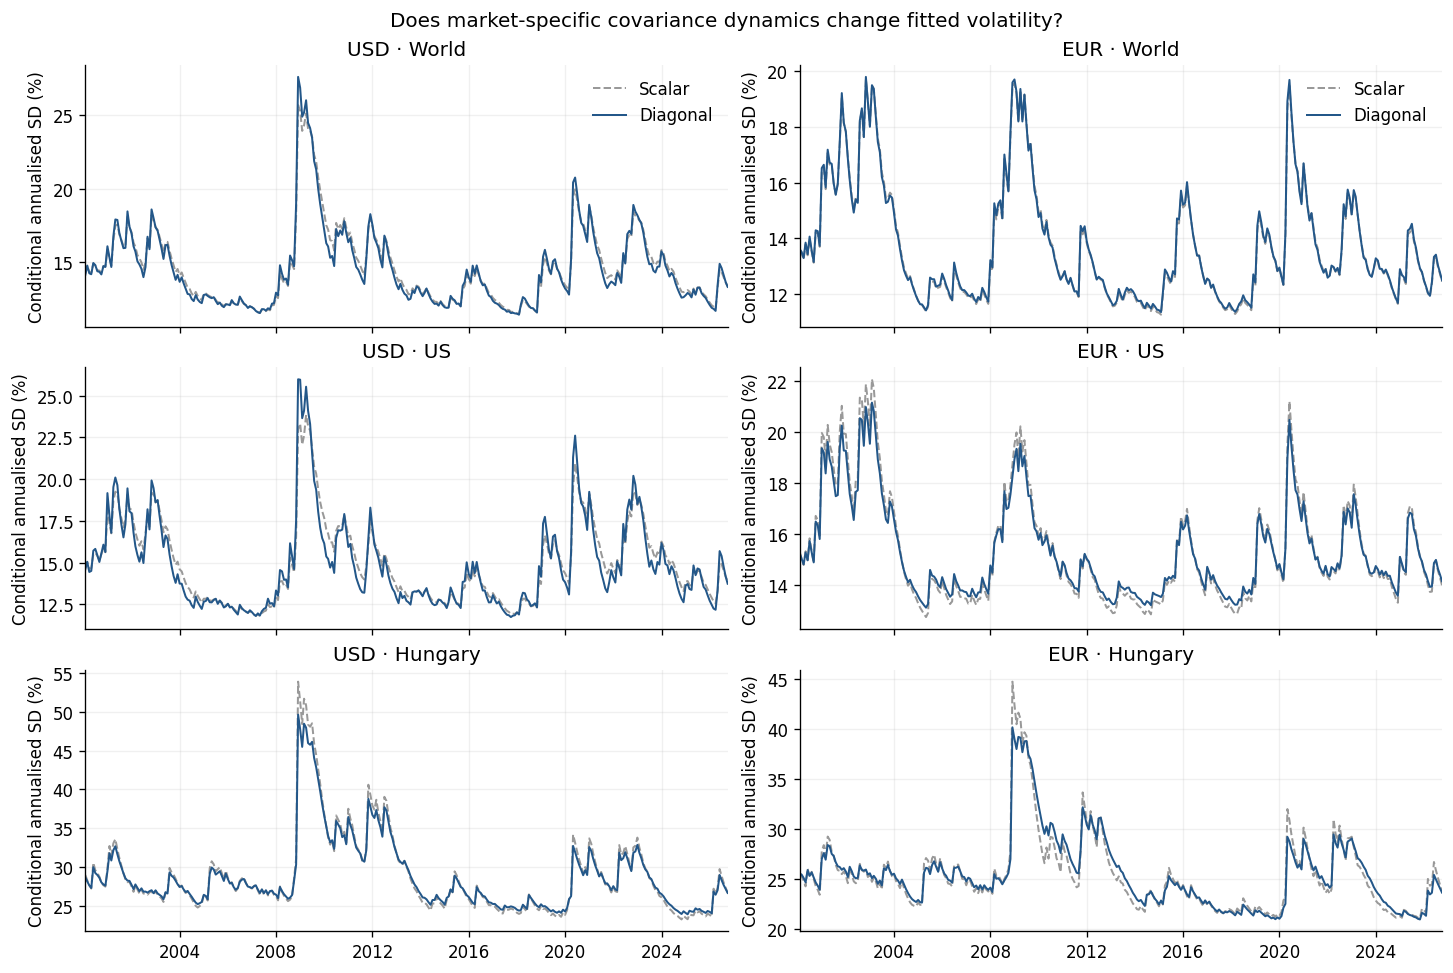

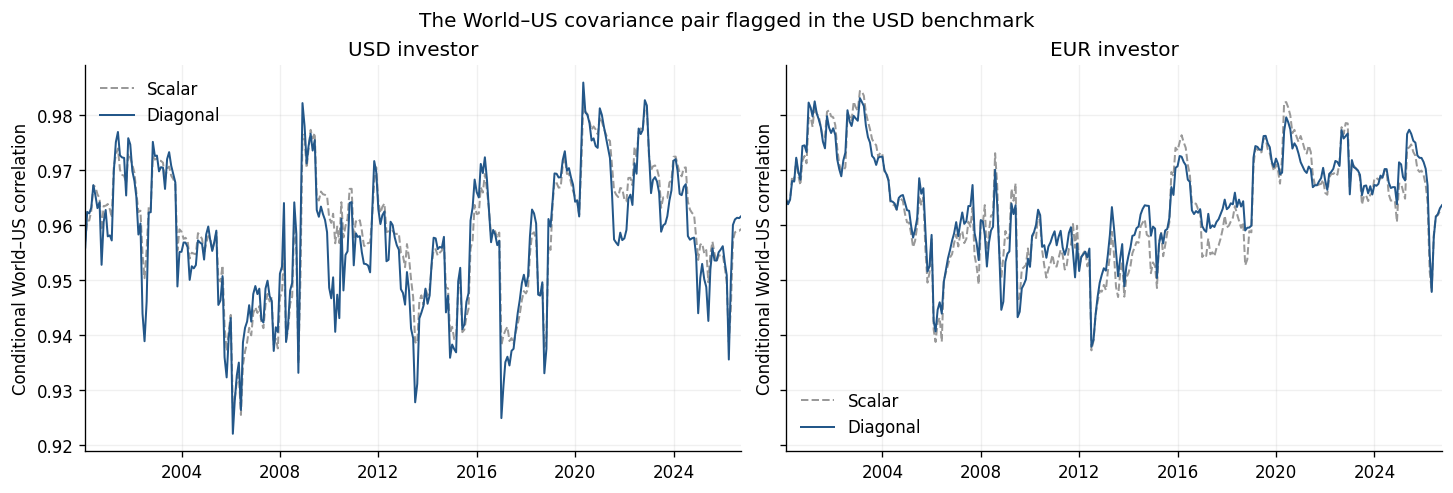

In [9]:
dates = data.index.to_timestamp("M")
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, layout="constrained")
for col, currency in enumerate(["USD", "EUR"]):
    for row, asset in enumerate(ASSETS):
        ax = axes[row, col]
        for name, collection, color, style in [("Scalar", baseline_fits, "#999999", "--"),
                                                ("Diagonal", fits, "#235789", "-")]:
            H = collection[f"{currency}_world_local"]["filter"]["H"]
            ax.plot(dates, np.sqrt(12 * H[:, row, row]), label=name, color=color, ls=style, lw=1.2)
        ax.set(title=f"{currency} · {asset}", ylabel="Conditional annualised SD (%)", xlim=(dates[0], dates[-1]))
        if row == 0: ax.legend(frameon=False)
fig.suptitle("Does market-specific covariance dynamics change fitted volatility?")
plt.savefig(OUT / "01_volatility_comparison.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout="constrained")
for ax, currency in zip(axes, ["USD", "EUR"]):
    for name, collection, color, style in [("Scalar", baseline_fits, "#999999", "--"),
                                            ("Diagonal", fits, "#235789", "-")]:
        H = collection[f"{currency}_world_local"]["filter"]["H"]
        correlation = H[:, 0, 1] / np.sqrt(H[:, 0, 0] * H[:, 1, 1])
        ax.plot(dates, correlation, label=name, color=color, ls=style, lw=1.2)
    ax.set(title=f"{currency} investor", ylabel="Conditional World–US correlation", xlim=(dates[0], dates[-1]))
    ax.legend(frameon=False)
fig.suptitle("The World–US covariance pair flagged in the USD benchmark")
plt.savefig(OUT / "02_correlation_comparison.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close()

## 8. Save and discuss the comparison

The final table uses the world/local pricing system. Negative changes in AIC/BIC favour the diagonal
specification. `variance_flags` counts assets with either squared-residual or ARCH p < 0.05;
`cross_flags` counts flagged pairs. These exploratory counts help locate remaining problems, rather
than define an automatic model-selection rule. The two local prices are tested jointly, and the
Hungarian price is also shown separately. Currency prices and conditional instruments are still absent.

In [10]:
summary_rows, comparison_rows = [], []
for currency in ["USD", "EUR"]:
    for model in ["world_only", "world_local"]:
        key = f"{currency}_{model}"
        baseline = baseline_fits[key]
        ll = -baseline["filter"]["losses"].sum()
        k, n = len(baseline["theta"]), len(data)
        comparison_rows.append({"perspective": currency, "model": model,
            "scalar_AIC": -2 * ll + 2 * k, "diagonal_AIC": fit_table.loc[(currency, model), "AIC"],
            "delta_AIC": fit_table.loc[(currency, model), "AIC"] - (-2 * ll + 2 * k),
            "scalar_BIC": -2 * ll + np.log(n) * k, "diagonal_BIC": fit_table.loc[(currency, model), "BIC"],
            "delta_BIC": fit_table.loc[(currency, model), "BIC"] - (-2 * ll + np.log(n) * k)})
    for name, collection in [("scalar", baseline_fits), ("diagonal", fits)]:
        key = f"{currency}_world_local"
        fit = collection[key]
        covariance = fit["covariance"]
        valid = np.isfinite(covariance).all()
        local = fit["theta"][1:3]
        statistic = local @ np.linalg.solve(covariance[1:3, 1:3], local) if valid else np.nan
        hu = fit["filter"]["prices"][2]
        se = PRICE_SCALE * np.sqrt(covariance[2, 2]) if valid else np.nan
        marginal = residual_table.loc[(currency, "world_local", name)]
        cross = cross_table.loc[(currency, "world_local", name)]
        summary_rows.append({"perspective": currency, "covariance_model": name,
            "Hungary_price": hu, "Hungary_price_p": 2 * norm.sf(abs(hu / se)) if valid else np.nan,
            "local_joint_p": chi2.sf(statistic, 2) if valid else np.nan,
            "mean_flags": int(marginal["LB_z_p"].lt(0.05).sum()),
            "variance_flags": int((marginal["LB_z_squared_p"].lt(0.05) | marginal["ARCH_LM_p"].lt(0.05)).sum()),
            "cross_flags": int(cross["LB_product_p"].lt(0.05).sum())})
comparison = pd.DataFrame(comparison_rows).set_index(["perspective", "model"]).sort_index()
summary = pd.DataFrame(summary_rows).set_index(["perspective", "covariance_model"]).sort_index()
final_table = summary.copy()
for currency in ["USD", "EUR"]:
    for name in ["scalar", "diagonal"]:
        final_table.loc[(currency, name), "AIC"] = comparison.loc[(currency, "world_local"), f"{name}_AIC"]
        final_table.loc[(currency, name), "BIC"] = comparison.loc[(currency, "world_local"), f"{name}_BIC"]
        final_table.loc[(currency, name), "common_dynamics_p"] = (wald_table.loc[(currency, "world_local", "Common covariance dynamics"), "robust_p_value"] if name == "diagonal" else np.nan)
tables = {"fit_summary.csv": fit_table, "risk_prices.csv": price_table, "restriction_tests.csv": wald_table,
          "dynamics.csv": dynamics_table, "starting_points.csv": starts_table,
          "residual_diagnostics.csv": residual_table, "cross_covariance_diagnostics.csv": cross_table,
          "model_comparison.csv": comparison, "summary.csv": final_table}
for name, table in tables.items():
    table.to_csv(OUT / name, float_format="%.17g", lineterminator="\n")
for key, fit in fits.items():
    np.savez(OUT / f"parameters_{key}.npz", theta=fit["theta"], robust_covariance=fit["covariance"],
             H=fit["filter"]["H"], mu=fit["filter"]["mu"], residuals=fit["filter"]["errors"])
record = {"model_version": MODEL_VERSION, "model_code_sha256": model_code_sha256, "source_snapshot": SNAPSHOT,
          "source_dataset_sha256": manifest["exports"]["dataset.csv"], "baseline_file_sha256": baseline_hashes,
          "first": str(data.index[0]), "last": str(data.index[-1]), "observations": len(data),
          "return_unit": "monthly log percentage points", "assets": ASSETS,
          "covariance": "diagonal BEKK; free CC' intercept; nonnegative diagonal A,B; H0=stationary innovation covariance",
          "risk_prices": "constant, unrestricted sign; currency terms omitted", "test_lags": TEST_LAGS,
          "packages": versions, "python": platform.python_version()}
(OUT / "estimation_manifest.json").write_text(json.dumps(record, indent=2, sort_keys=True) + "\n")
if hashlib.sha256((source / "dataset.csv").read_bytes()).hexdigest() != manifest["exports"]["dataset.csv"]:
    raise ValueError("Frozen source checksum changed.")
display(comparison.round(3))
display(Markdown("**Final summary — same 321-month sample**".replace("321", str(len(data)))))
display(final_table.round(4))
for currency in ["USD", "EUR"]:
    row = comparison.loc[(currency, "world_local")]
    diagnostic = final_table.loc[(currency, "diagonal")]
    display(Markdown(f"**{currency}:** diagonal minus scalar AIC = **{row['delta_AIC']:+.2f}**, "
        f"BIC = **{row['delta_BIC']:+.2f}**. Diagonal residual screens flag "
        f"{int(diagnostic['mean_flags'])} mean series, {int(diagnostic['variance_flags'])} variance series "
        f"and {int(diagnostic['cross_flags'])} covariance pairs at nominal 5%. "
        f"Joint local-price p = **{diagnostic['local_joint_p']:.3f}**; "
        f"Hungary-only p = **{diagnostic['Hungary_price_p']:.3f}**. "
        f"These are conditional results, not proof of integration or zero currency risk."))
if comparison["delta_AIC"].gt(0).all() and comparison["delta_BIC"].gt(0).all():
    display(Markdown("**Working choice:** both AIC and BIC favour the scalar benchmark in each "
        "perspective and pricing restriction. Keep it as the parsimonious reference and the diagonal "
        "model as a sensitivity check. Remaining covariance flags keep pricing inference provisional."))
display(Markdown("**Next research step:** retain both covariance fits for sensitivity analysis when "
    "adding currency risk. Any remaining residual dependence limits structural inference; reassess it "
    "in the expanded system. Handle the earlier EUR/HUF mean-dependence finding when FX is added. "
    "Inflation instruments remain deferred. "
    f"Saved outputs: `{OUT.relative_to(ROOT)}`. The frozen dataset is unchanged."))

scalar_AIC  diagonal_AIC  delta_AIC  scalar_BIC  \
perspective model                                                          
EUR         world_local    4871.648      4876.873      5.225    4913.134   
            world_only     4870.227      4875.109      4.881    4904.170   
USD         world_local    4918.610      4924.827      6.217    4960.096   
            world_only     4917.799      4923.890      6.091    4951.742   

                         diagonal_BIC  delta_BIC  
perspective model                                 
EUR         world_local      4933.445     20.311  
            world_only       4924.137     19.967  
USD         world_local      4981.398     21.302  
            world_only       4972.919     21.176

**Final summary — same 321-month sample**

Hungary_price  Hungary_price_p  local_joint_p  \
perspective covariance_model                                                  
EUR         diagonal                 0.0030           0.6473         0.4031   
            scalar                   0.0045           0.4801         0.3468   
USD         diagonal                 0.0009           0.8528         0.2943   
            scalar                  -0.0001           0.9898         0.2687   

                              mean_flags  variance_flags  cross_flags  \
perspective covariance_model                                            
EUR         diagonal                   0               0            0   
            scalar                     0               0            0   
USD         diagonal                   0               1            1   
            scalar                     0               2            1   

                                    AIC        BIC  common_dynamics_p  
perspective covariance_model                                           
EUR         diagonal          4876.8732  4933.4448             0.7176  
            scalar            4871.6479  4913.1338                NaN  
USD         diagonal          4924.8268  4981.3984             0.9691  
            scalar            4918.6102  4960.0960                NaN

**USD:** diagonal minus scalar AIC = **+6.22**, BIC = **+21.30**. Diagonal residual screens flag 0 mean series, 1 variance series and 1 covariance pairs at nominal 5%. Joint local-price p = **0.294**; Hungary-only p = **0.853**. These are conditional results, not proof of integration or zero currency risk.

**EUR:** diagonal minus scalar AIC = **+5.23**, BIC = **+20.31**. Diagonal residual screens flag 0 mean series, 0 variance series and 0 covariance pairs at nominal 5%. Joint local-price p = **0.403**; Hungary-only p = **0.647**. These are conditional results, not proof of integration or zero currency risk.

**Working choice:** both AIC and BIC favour the scalar benchmark in each perspective and pricing restriction. Keep it as the parsimonious reference and the diagonal model as a sensitivity check. Remaining covariance flags keep pricing inference provisional.

**Next research step:** retain both covariance fits for sensitivity analysis when adding currency risk. Any remaining residual dependence limits structural inference; reassess it in the expanded system. Handle the earlier EUR/HUF mean-dependence finding when FX is added. Inflation instruments remain deferred. Saved outputs: `output/04_covariance_comparison/fixed_2026-11-13/2000-01_2026-09`. The frozen dataset is unchanged.